In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Problema 1

In [4]:
for _v in [v for v in list(globals()) if v.startswith('pregunta_')]:
    del globals()[_v]

Considere el proyecto cuyo cuadro de prelaciones y duraciones (en semanas) se adjunta.

In [5]:
pregunta_1 = "1. Calcule el calendario del proyecto con las holguras total, libre e independiente.  "
pregunta_2 = "2. F y H son consecutivas y tienen la misma holgura total. El responsable de F pide retrasarla 12 semanas y el de H también. ¿Pueden concederse las dos peticiones sin alargar el proyecto? Razónelo antes de calcular.  "
pregunta_3 = "3. Compruébelo: recalcule el calendario con F retrasada 12 semanas y después con las dos retrasadas.  "
pregunta_4 = "4. ¿Qué holgura expresa cuánto puede retrasarse cada una sin quitarle margen a la otra? ¿Cómo repartiría las 12 semanas entre F y H?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule el calendario del proyecto con las holguras total, libre e independiente.  

2. F y H son consecutivas y tienen la misma holgura total. El responsable de F pide retrasarla 12 semanas y el de H también. ¿Pueden concederse las dos peticiones sin alargar el proyecto? Razónelo antes de calcular.  

3. Compruébelo: recalcule el calendario con F retrasada 12 semanas y después con las dos retrasadas.  

4. ¿Qué holgura expresa cuánto puede retrasarse cada una sin quitarle margen a la otra? ¿Cómo repartiría las 12 semanas entre F y H?  

In [6]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado-p1
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 7       ),
    ('B'     , '---'      , 3       ),
    ('C'     , '---'      , 4       ),
    ('D'     , 'A,C'      , 7       ),
    ('E'     , 'D'        , 1       ),
    ('F'     , 'B'        , 4       ),
    ('G'     , 'E'        , 5       ),
    ('H'     , 'F'        , 1       ),
    ('I'     , 'G,H'      , 3       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,7
B,---,3
C,---,4
D,"A,C",7
E,D,1
F,B,4
G,E,5
H,F,1
I,"G,H",3


## Solución del problema 1

In [7]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
duracion_proyecto = proyecto.duration(datos_proyecto['duration'])

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Calcule el calendario del proyecto con las holguras total, libre e independiente.  

Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

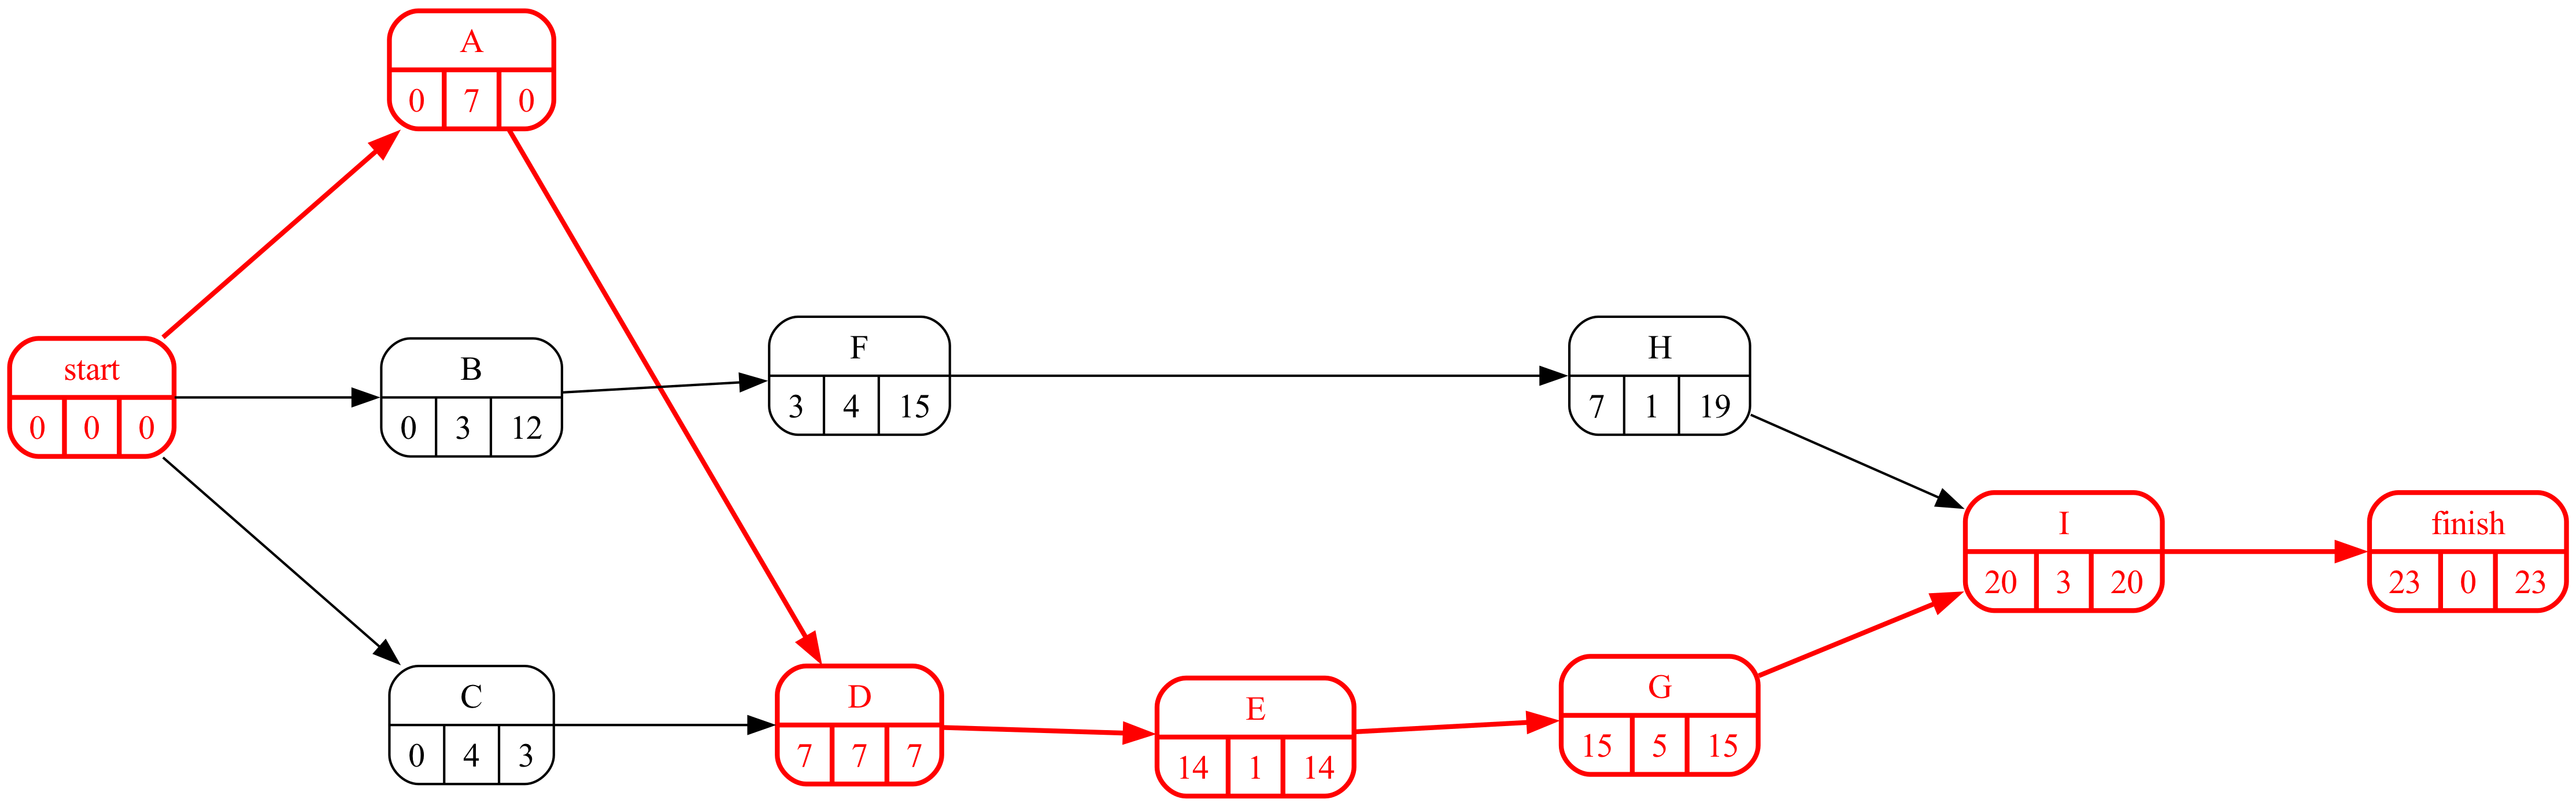

In [9]:
#| fig-cap: "Grafo Roy con tiempos y camino crítico"
#| label: fig-pert-p1
proyecto.display_roy_pasos(datos_proyecto['duration'])

In [10]:
#| tbl-cap: "Calendario y holguras"
#| label: tbl-calendario-p1
calendario = proyecto.calendar(datos_proyecto['duration'])
calendario

,inicio_mas_temprano,inicio_mas_tardio,fin_mas_temprano,fin_mas_tardio,H_libre,H_independiente,H_total,duracion
activity,,,,,,,,
A,0,0,7,7,0,0,0,7
B,0,12,3,15,0,0,12,3
C,0,3,4,7,3,3,3,4
D,7,7,14,14,0,0,0,7
E,14,14,15,15,0,0,0,1
F,3,15,7,19,0,0,12,4
G,15,15,20,20,0,0,0,5
H,7,19,8,20,12,0,12,1
I,20,20,23,23,0,0,0,3


Con los números sustituidos, actividad a actividad (ES, EF, LS y LF son inicio y fin más tempranos y más tardíos; «pred.» y «suc.» las predecesoras y sucesoras inmediatas):

In [11]:
#| tbl-cap: "Cálculo paso a paso de fechas y holguras"
#| label: tbl-holgurasPaso-p1
detalle_holguras(calendario, prelaciones)

,ES = máx EF pred.,EF = ES + d,LF = mín LS suc.,LS = LF − d,H_total = LS − ES,H_libre = mín ES suc. − EF,"H_indep. = máx(0, mín ES suc. − máx LF pred. − d)"
actividad,,,,,,,
A,inicial → 0,0 + 7 = 7,mín(D: 7) = 7,7 − 7 = 0,0 − 0 = 0,7 − 7 = 0,"máx(0, 7 − 0 − 7) = 0"
B,inicial → 0,0 + 3 = 3,mín(F: 15) = 15,15 − 3 = 12,12 − 0 = 12,3 − 3 = 0,"máx(0, 3 − 0 − 3) = 0"
C,inicial → 0,0 + 4 = 4,mín(D: 7) = 7,7 − 4 = 3,3 − 0 = 3,7 − 4 = 3,"máx(0, 7 − 0 − 4) = 3"
D,"máx(A: 7, C: 4) = 7",7 + 7 = 14,mín(E: 14) = 14,14 − 7 = 7,7 − 7 = 0,14 − 14 = 0,"máx(0, 14 − 7 − 7) = 0"
E,máx(D: 14) = 14,14 + 1 = 15,mín(G: 15) = 15,15 − 1 = 14,14 − 14 = 0,15 − 15 = 0,"máx(0, 15 − 14 − 1) = 0"
F,máx(B: 3) = 3,3 + 4 = 7,mín(H: 19) = 19,19 − 4 = 15,15 − 3 = 12,7 − 7 = 0,"máx(0, 7 − 15 − 4) = 0"
G,máx(E: 15) = 15,15 + 5 = 20,mín(I: 20) = 20,20 − 5 = 15,15 − 15 = 0,20 − 20 = 0,"máx(0, 20 − 15 − 5) = 0"
H,máx(F: 7) = 7,7 + 1 = 8,mín(I: 20) = 20,20 − 1 = 19,19 − 7 = 12,20 − 8 = 12,"máx(0, 20 − 19 − 1) = 0"
I,"máx(G: 20, H: 8) = 20",20 + 3 = 23,final → 23,23 − 3 = 20,20 − 20 = 0,23 (fin) − 23 = 0,"máx(0, 23 − 20 − 3) = 0"


## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. F y H son consecutivas y tienen la misma holgura total. El responsable de F pide retrasarla 12 semanas y el de H también. ¿Pueden concederse las dos peticiones sin alargar el proyecto? Razónelo antes de calcular.  

No. La holgura total de F y la de H son la *misma* holgura: la de la cadena en la que están. F tiene holgura libre cero, así que cualquier retraso suyo mueve el inicio de H y le consume holgura. Si F gasta las 12 semanas, H se queda sin ninguna; si además H se retrasa, el proyecto se alarga.

## Apartado 3

In [13]:
display(Markdown(pregunta_3))

3. Compruébelo: recalcule el calendario con F retrasada 12 semanas y después con las dos retrasadas.  

In [14]:
X, Y, h = 'F', 'H', 12
d1 = datos_proyecto['duration'].copy(); d1[X] += h
d2 = d1.copy(); d2[Y] += h
cal1, cal2 = proyecto.calendar(d1), proyecto.calendar(d2)
pd.DataFrame({'original': calendario.loc[[X, Y], 'H_total'], f'{X} retrasada {h}': cal1.loc[[X, Y], 'H_total'],
              'las dos retrasadas': cal2.loc[[X, Y], 'H_total']})

,original,F retrasada 12,las dos retrasadas
activity,,,
F,12,0,0
H,12,0,0


In [15]:
Markdown(f'Duración del proyecto: {duracion_proyecto} semanas en la planificación original, {proyecto.duration(d1)} con {X} retrasada '
         f'y **{proyecto.duration(d2)}** con las dos retrasadas: el segundo retraso ya no cabe en la holgura.')

Duración del proyecto: 23 semanas en la planificación original, 23 con F retrasada y **35** con las dos retrasadas: el segundo retraso ya no cabe en la holgura.

## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. ¿Qué holgura expresa cuánto puede retrasarse cada una sin quitarle margen a la otra? ¿Cómo repartiría las 12 semanas entre F y H?  

In [17]:
Markdown(f'''La holgura libre de {X} es {int(calendario.loc[X, "H_libre"])}: es lo que puede retrasarse sin mover a {Y}. La holgura independiente de {Y} es {int(calendario.loc[Y, "H_independiente"])}: lo que puede retrasarse {Y} aunque {X} acabe lo más tarde posible. Las {h} semanas son un recurso compartido de la cadena: cualquier reparto x + y ≤ {h} entre {X} y {Y} respeta el plazo; lo que no es posible es que cada una disponga de {h} por su cuenta.''')

La holgura libre de F es 0: es lo que puede retrasarse sin mover a H. La holgura independiente de H es 0: lo que puede retrasarse H aunque F acabe lo más tarde posible. Las 12 semanas son un recurso compartido de la cadena: cualquier reparto x + y ≤ 12 entre F y H respeta el plazo; lo que no es posible es que cada una disponga de 12 por su cuenta.

# Problema 2

In [18]:
for _v in [v for v in list(globals()) if v.startswith('pregunta_')]:
    del globals()[_v]

Considere el proyecto cuyo cuadro de prelaciones, duraciones medias y desviaciones típicas (en semanas) se adjunta.

In [19]:
pregunta_1 = "1. Determine la duración media del proyecto y su(s) camino(s) crítico(s).  "
pregunta_2 = "2. Calcule la varianza y la desviación típica de la duración del proyecto. ¿Qué ruta crítica debe usarse para ello? Razone la respuesta.  "
pregunta_3 = "3. ¿Qué probabilidad hay de terminar el proyecto en 34 semanas o menos?  "
pregunta_4 = "4. ¿Qué probabilidad hay de terminar entre las semanas 31 y 34?  "
pregunta_5 = "5. ¿Qué duración puede comprometerse con el cliente con una probabilidad del 90% de cumplirla?  "
pregunta_6 = "6. ¿Qué probabilidad hay de terminar en la duración media o antes? ¿Puede garantizarse esa duración con un 90% de probabilidad sin modificar el proyecto?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Determine la duración media del proyecto y su(s) camino(s) crítico(s).  

2. Calcule la varianza y la desviación típica de la duración del proyecto. ¿Qué ruta crítica debe usarse para ello? Razone la respuesta.  

3. ¿Qué probabilidad hay de terminar el proyecto en 34 semanas o menos?  

4. ¿Qué probabilidad hay de terminar entre las semanas 31 y 34?  

5. ¿Qué duración puede comprometerse con el cliente con una probabilidad del 90% de cumplirla?  

6. ¿Qué probabilidad hay de terminar en la duración media o antes? ¿Puede garantizarse esa duración con un 90% de probabilidad sin modificar el proyecto?  

In [20]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado-p2
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, standard_deviation
    ('A'     , '---'      , 7       , 0.1               ),
    ('B'     , '---'      , 4       , 0.8               ),
    ('C'     , '---'      , 7       , 0.4               ),
    ('D'     , 'A,B,C'    , 6       , 0.1               ),
    ('E'     , 'D'        , 3       , 0.3               ),
    ('F'     , 'E'        , 4       , 0.8               ),
    ('G'     , 'F'        , 3       , 1                 ),
    ('H'     , 'G'        , 6       , 0.4               ),
    ('I'     , 'H'        , 3       , 0.3               ),
    ('J'     , 'H'        , 2       , 0.4               ),
], columns=['activity', 'predecessor', 'duration', 'standard_deviation']).set_index('activity')
datos_enunciado

,predecessor,duration,standard_deviation
activity,,,
A,---,7,0.1
B,---,4,0.8
C,---,7,0.4
D,"A,B,C",6,0.1
E,D,3,0.3
F,E,4,0.8
G,F,3,1.0
H,G,6,0.4
I,H,3,0.3


El proyecto corresponde a el lanzamiento de una aplicación móvil; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [21]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones-p2
descripciones = pd.Series({
    'A': 'Estudio de requisitos',
    'B': 'Diseño de la arquitectura',
    'C': 'Diseño de interfaz y prototipo',
    'D': 'Base de datos y modelo',
    'E': 'API del servidor',
    'F': 'Pantallas principales',
    'G': 'Módulo de pagos',
    'H': 'Notificaciones y sincronización',
    'I': 'Pruebas de integración',
    'J': 'Pruebas con usuarios',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Estudio de requisitos
B,Diseño de la arquitectura
C,Diseño de interfaz y prototipo
D,Base de datos y modelo
E,API del servidor
F,Pantallas principales
G,Módulo de pagos
H,Notificaciones y sincronización
I,Pruebas de integración
J,Pruebas con usuarios


## Solución del problema 2

In [22]:
datos_proyecto = datos_enunciado.copy()
datos_proyecto['variance'] = datos_proyecto['standard_deviation'] ** 2
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [23]:
display(Markdown(pregunta_1))

1. Determine la duración media del proyecto y su(s) camino(s) crítico(s).  

Cálculo de los tiempos tempranos y tardíos de los sucesos y de las holguras totales paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

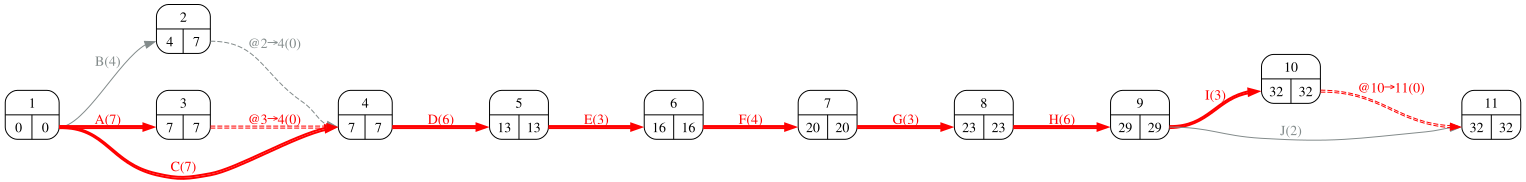

In [24]:
#| fig-cap: "Grafo PERT con tiempos de los nodos y camino crítico"
#| label: fig-pert-p2
proyecto.display_pert_pasos(datos_proyecto['duration'])

In [25]:
#| tbl-cap: "Holgura total de las actividades"
#| label: tbl-holguras-p2
resultados_pert = proyecto.calculate_pert(durations=datos_proyecto['duration'])
resultados_pert['activities'].T

,@10→11,@2→4,@3→4,A,B,C,D,E,F,G,H,I,J
H_total,0,3,0,0,3,0,0,0,0,0,0,0,1


In [26]:
duracion_media = proyecto.duration(datos_proyecto['duration'])
rutas_criticas = proyecto.critical_path(datos_proyecto['duration'])
for nombre, acts in rutas_criticas.items():
    print(f'{nombre}: {" - ".join(acts)}')
Markdown(f'La duración media del proyecto es {duracion_media} semanas y tiene {len(rutas_criticas)} ruta(s) crítica(s).')

Route_1: A - D - E - F - G - H - I
Route_5: C - D - E - F - G - H - I


La duración media del proyecto es 32 semanas y tiene 2 ruta(s) crítica(s).

## Apartado 2

In [27]:
display(Markdown(pregunta_2))

2. Calcule la varianza y la desviación típica de la duración del proyecto. ¿Qué ruta crítica debe usarse para ello? Razone la respuesta.  

Por el teorema central del límite, la duración de una ruta es aproximadamente normal con media la suma de las medias y varianza la suma de las varianzas de sus actividades. Para el proyecto se toma la ruta crítica; si hay varias, la de mayor varianza, que es la hipótesis más prudente (la verdadera distribución del máximo de varias rutas no es normal, y el método PERT la aproxima así).

In [28]:
#| tbl-cap: "Varianza de las rutas críticas"
#| label: tbl-varianzaRutas-p2
desviacion_proyecto, varianza_rutas = proyecto.standard_deviation(durations=datos_proyecto['duration'],
                                                                   variances=datos_proyecto['variance'])
varianza_rutas

,Activities,Variance
Route_1,"A, D, E, F, G, H, I",2.00
Route_5,"C, D, E, F, G, H, I",2.15


Sumando actividad a actividad a lo largo de cada ruta (la media de una ruta es la suma de las medias; su varianza, la suma de las varianzas):

In [29]:
#| tbl-cap: "Media y varianza de cada ruta, sumando sus actividades"
#| label: tbl-rutasPaso-p2
R = proyecto.path_matrix(dummies=False)
detalle_medias = detalle_rutas(R, datos_proyecto['duration'][R.columns], 'media')
detalle_varianzas = detalle_rutas(R, datos_proyecto['variance'][R.columns], 'varianza', 3)
pd.concat([detalle_medias, detalle_varianzas.drop(columns='actividades')], axis=1)

,actividades,media = suma,media,varianza = suma,varianza
Route_1,A - D - E - F - G - H - I,A(7) + D(6) + E(3) + F(4) + G(3) + H(6) + I(3)...,32.0,A(0.010) + D(0.010) + E(0.090) + F(0.640) + G(...,2.0
Route_2,A - D - E - F - G - H - J,A(7) + D(6) + E(3) + F(4) + G(3) + H(6) + J(2)...,31.0,A(0.010) + D(0.010) + E(0.090) + F(0.640) + G(...,2.07
Route_3,B - D - E - F - G - H - I,B(4) + D(6) + E(3) + F(4) + G(3) + H(6) + I(3)...,29.0,B(0.640) + D(0.010) + E(0.090) + F(0.640) + G(...,2.63
Route_4,B - D - E - F - G - H - J,B(4) + D(6) + E(3) + F(4) + G(3) + H(6) + J(2)...,28.0,B(0.640) + D(0.010) + E(0.090) + F(0.640) + G(...,2.7
Route_5,C - D - E - F - G - H - I,C(7) + D(6) + E(3) + F(4) + G(3) + H(6) + I(3)...,32.0,C(0.160) + D(0.010) + E(0.090) + F(0.640) + G(...,2.15
Route_6,C - D - E - F - G - H - J,C(7) + D(6) + E(3) + F(4) + G(3) + H(6) + J(2)...,31.0,C(0.160) + D(0.010) + E(0.090) + F(0.640) + G(...,2.22


In [30]:
Markdown(f'La varianza del proyecto es {desviacion_proyecto**2:.3f} y su desviación típica {desviacion_proyecto:.3f} semanas.')

La varianza del proyecto es 2.150 y su desviación típica 1.466 semanas.

## Apartado 3

In [31]:
display(Markdown(pregunta_3))

3. ¿Qué probabilidad hay de terminar el proyecto en 34 semanas o menos?  

Con $T \sim N(\mu, \sigma)$: $P(T \le t) = \Phi\left(\frac{t - \mu}{\sigma}\right)$.

In [32]:
plazo = 34
z = (plazo - duracion_media) / desviacion_proyecto
probabilidad_plazo = norm.cdf(z)
Markdown(f'z = ({plazo} − {duracion_media}) / {desviacion_proyecto:.3f} = {z:.3f}, luego P(T ≤ {plazo}) = Φ({z:.3f}) = {probabilidad_plazo:.4f} ({probabilidad_plazo*100:.1f} %).')

z = (34 − 32) / 1.466 = 1.364, luego P(T ≤ 34) = Φ(1.364) = 0.9137 (91.4 %).

## Apartado 4

In [33]:
display(Markdown(pregunta_4))

4. ¿Qué probabilidad hay de terminar entre las semanas 31 y 34?  

In [34]:
t_a, t_b = 31, 34
p_b = norm.cdf((t_b - duracion_media) / desviacion_proyecto)
p_a = norm.cdf((t_a - duracion_media) / desviacion_proyecto)
Markdown(f'P({t_a} < T ≤ {t_b}) = Φ({(t_b - duracion_media) / desviacion_proyecto:.3f}) − Φ({(t_a - duracion_media) / desviacion_proyecto:.3f}) '
         f'= {p_b:.4f} − {p_a:.4f} = {p_b - p_a:.4f} ({(p_b - p_a)*100:.1f} %).')

P(31 < T ≤ 34) = Φ(1.364) − Φ(-0.682) = 0.9137 − 0.2476 = 0.6661 (66.6 %).

## Apartado 5

In [35]:
display(Markdown(pregunta_5))

5. ¿Qué duración puede comprometerse con el cliente con una probabilidad del 90% de cumplirla?  

Se busca $t$ tal que $P(T \le t) = p$, es decir, $t = \mu + z_p\,\sigma$ con $z_p = \Phi^{-1}(p)$.

In [36]:
probabilidad_objetivo = 0.9
z_p = norm.ppf(probabilidad_objetivo)
duracion_comprometida = duracion_media + z_p * desviacion_proyecto
Markdown(f'z = {z_p:.3f}; t = {duracion_media} + {z_p:.3f} × {desviacion_proyecto:.3f} = {duracion_comprometida:.2f} semanas. '
         f'Como el calendario se mide en semanas enteras, se comprometerían {int(np.ceil(duracion_comprometida))} semanas.')

z = 1.282; t = 32 + 1.282 × 1.466 = 33.88 semanas. Como el calendario se mide en semanas enteras, se comprometerían 34 semanas.

## Apartado 6

In [37]:
display(Markdown(pregunta_6))

6. ¿Qué probabilidad hay de terminar en la duración media o antes? ¿Puede garantizarse esa duración con un 90% de probabilidad sin modificar el proyecto?  

In [38]:
Markdown(f'''La duración media es la mediana de la normal, así que P(T ≤ {duracion_media}) = 0.5: sólo la mitad de las veces se terminaría en la duración media o antes. Para garantizarla con un 90% haría falta que la media del proyecto fuera {duracion_media} − {z_p:.3f} × {desviacion_proyecto:.3f} = {duracion_media - z_p * desviacion_proyecto:.2f} semanas, es decir, reducir el proyecto (acortando actividades críticas) o reducir su varianza. Sin tocar el proyecto no es posible.''')

La duración media es la mediana de la normal, así que P(T ≤ 32) = 0.5: sólo la mitad de las veces se terminaría en la duración media o antes. Para garantizarla con un 90% haría falta que la media del proyecto fuera 32 − 1.282 × 1.466 = 30.12 semanas, es decir, reducir el proyecto (acortando actividades críticas) o reducir su varianza. Sin tocar el proyecto no es posible.

# Problema 3

In [39]:
for _v in [v for v in list(globals()) if v.startswith('pregunta_')]:
    del globals()[_v]

Considere el proyecto cuyo cuadro de prelaciones, duraciones planificadas (semanas) y presupuesto por actividad (BAC, en k€) se adjunta. El coste planificado de cada actividad se reparte uniformemente a lo largo de su duración.

In [40]:
#| tbl-cap: "Planificación del proyecto"
#| label: tbl-datosEnunciado-p3
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, BAC
    ('A'     , '---'      , 3       , 20 ),
    ('B'     , '---'      , 4       , 50 ),
    ('C'     , '---'      , 6       , 40 ),
    ('D'     , 'A,B,C'    , 4       , 60 ),
    ('E'     , 'B,C'      , 3       , 60 ),
    ('F'     , 'D,E'      , 2       , 10 ),
    ('G'     , 'D'        , 2       , 50 ),
    ('H'     , 'F'        , 4       , 30 ),
], columns=['activity', 'predecessor', 'duration', 'BAC']).set_index('activity')
datos_enunciado

,predecessor,duration,BAC
activity,,,
A,---,3,20
B,---,4,50
C,---,6,40
D,"A,B,C",4,60
E,"B,C",3,60
F,"D,E",2,10
G,D,2,50
H,F,4,30


Se han realizado tres puntos de control, al final de las semanas 5, 9 y 13. En cada uno se anotó, para cada actividad, las semanas trabajadas hasta ese momento, el coste real incurrido (k€) y el porcentaje realizado.

In [41]:
#| tbl-cap: "Punto de control 1 (final de la semana 5)"
#| label: tbl-seguimiento1-p3
seguimiento_1 = pd.DataFrame([
#  activity, actual_duration, AC, performed
    ('A'     , 4              , 20, 100      ),
    ('B'     , 5              , 41, 62       ),
    ('C'     , 5              , 33, 83       ),
    ('D'     , 0              , 0 , 0        ),
    ('E'     , 0              , 0 , 0        ),
    ('F'     , 0              , 0 , 0        ),
    ('G'     , 0              , 0 , 0        ),
    ('H'     , 0              , 0 , 0        ),
], columns=['activity', 'actual_duration', 'AC', 'performed']).set_index('activity')
seguimiento_1

,actual_duration,AC,performed
activity,,,
A,4,20,100
B,5,41,62
C,5,33,83
D,0,0,0
E,0,0,0
F,0,0,0
G,0,0,0
H,0,0,0


In [42]:
#| tbl-cap: "Punto de control 2 (final de la semana 9)"
#| label: tbl-seguimiento2-p3
seguimiento_2 = pd.DataFrame([
#  activity, actual_duration, AC, performed
    ('A'     , 4              , 20, 100      ),
    ('B'     , 8              , 65, 100      ),
    ('C'     , 6              , 40, 100      ),
    ('D'     , 1              , 11, 12       ),
    ('E'     , 1              , 30, 33       ),
    ('F'     , 0              , 0 , 0        ),
    ('G'     , 0              , 0 , 0        ),
    ('H'     , 0              , 0 , 0        ),
], columns=['activity', 'actual_duration', 'AC', 'performed']).set_index('activity')
seguimiento_2

,actual_duration,AC,performed
activity,,,
A,4,20,100
B,8,65,100
C,6,40,100
D,1,11,12
E,1,30,33
F,0,0,0
G,0,0,0
H,0,0,0


In [43]:
#| tbl-cap: "Punto de control 3 (final de la semana 13)"
#| label: tbl-seguimiento3-p3
seguimiento_3 = pd.DataFrame([
#  activity, actual_duration, AC, performed
    ('A'     , 4              , 20, 100      ),
    ('B'     , 8              , 65, 100      ),
    ('C'     , 6              , 40, 100      ),
    ('D'     , 5              , 56, 62       ),
    ('E'     , 3              , 90, 100      ),
    ('F'     , 0              , 0 , 0        ),
    ('G'     , 0              , 0 , 0        ),
    ('H'     , 0              , 0 , 0        ),
], columns=['activity', 'actual_duration', 'AC', 'performed']).set_index('activity')
seguimiento_3

,actual_duration,AC,performed
activity,,,
A,4,20,100
B,8,65,100
C,6,40,100
D,5,56,62
E,3,90,100
F,0,0,0
G,0,0,0
H,0,0,0


In [44]:
pregunta_1 = "1. Calcule PV, EV y AC en cada punto de control.  "
pregunta_2 = "2. Calcule CV, SV, CPI y SPI en cada punto de control y represente su evolución.  "
pregunta_3 = "3. Calcule en cada punto la estimación del coste final EAC = BAC / CPI y comente la tendencia.  "
pregunta_4 = "4. A la vista de la evolución, ¿el proyecto se está recuperando o deteriorando? ¿Qué decisiones tomaría tras el último punto de control?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule PV, EV y AC en cada punto de control.  

2. Calcule CV, SV, CPI y SPI en cada punto de control y represente su evolución.  

3. Calcule en cada punto la estimación del coste final EAC = BAC / CPI y comente la tendencia.  

4. A la vista de la evolución, ¿el proyecto se está recuperando o deteriorando? ¿Qué decisiones tomaría tras el último punto de control?  

## Solución del problema 3

In [45]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
BAC_total = float(datos_proyecto['BAC'].sum())
duracion_planificada = proyecto.duration(datos_proyecto['duration'])

Cálculo de los tiempos tempranos y tardíos de los sucesos y de las holguras totales paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

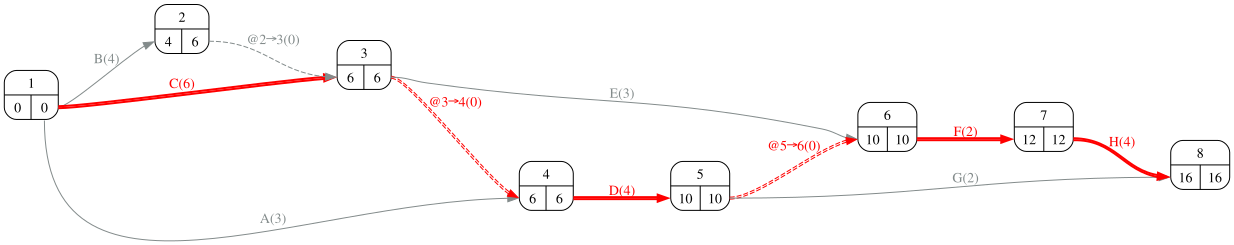

In [46]:
#| fig-cap: "Grafo PERT de la planificación"
#| label: fig-pert-p3
proyecto.display_pert_pasos(datos_proyecto['duration'])

## Apartado 1

In [47]:
display(Markdown(pregunta_1))

1. Calcule PV, EV y AC en cada punto de control.  

In [48]:
seguimientos = {5: seguimiento_1, 9: seguimiento_2, 13: seguimiento_3}
filas = {}
curvas = {}
for semana, seguimiento in seguimientos.items():
    datos_vg = pd.concat([datos_proyecto, seguimiento], axis=1)
    gantts = EarnedValue(proyecto.copy()).calcula_gantts(datos_vg, planned_durations_label='duration',
                                                          actual_durations_label='actual_duration', PV_label='BAC',
                                                          AC_label='AC', percentage_complete_label='performed', tikz=False)
    PV = float(gantts['acumulados'].loc[semana, 'PV'])
    EV = float((datos_vg['BAC'] * datos_vg['performed'] / 100).sum())
    AC = float(datos_vg['AC'].sum())
    filas[semana] = {'PV': PV, 'EV': EV, 'AC': AC}
indicadores = pd.DataFrame(filas).T
indicadores.index.name = 'semana'
indicadores.round(1)

,PV,EV,AC
semana,,,
5,103.3,84.2,94.0
9,215.0,137.0,166.0
13,297.5,207.2,271.0


## Apartado 2

In [49]:
display(Markdown(pregunta_2))

2. Calcule CV, SV, CPI y SPI en cada punto de control y represente su evolución.  

In [50]:
indicadores['CV'] = indicadores['EV'] - indicadores['AC']
indicadores['SV'] = indicadores['EV'] - indicadores['PV']
indicadores['CPI'] = indicadores['EV'] / indicadores['AC']
indicadores['SPI'] = indicadores['EV'] / indicadores['PV']
indicadores.round(3)

,PV,EV,AC,CV,SV,CPI,SPI
semana,,,,,,,
5,103.333,84.2,94.0,-9.8,-19.133,0.896,0.815
9,215.000,137.0,166.0,-29.0,-78.000,0.825,0.637
13,297.500,207.2,271.0,-63.8,-90.300,0.765,0.696


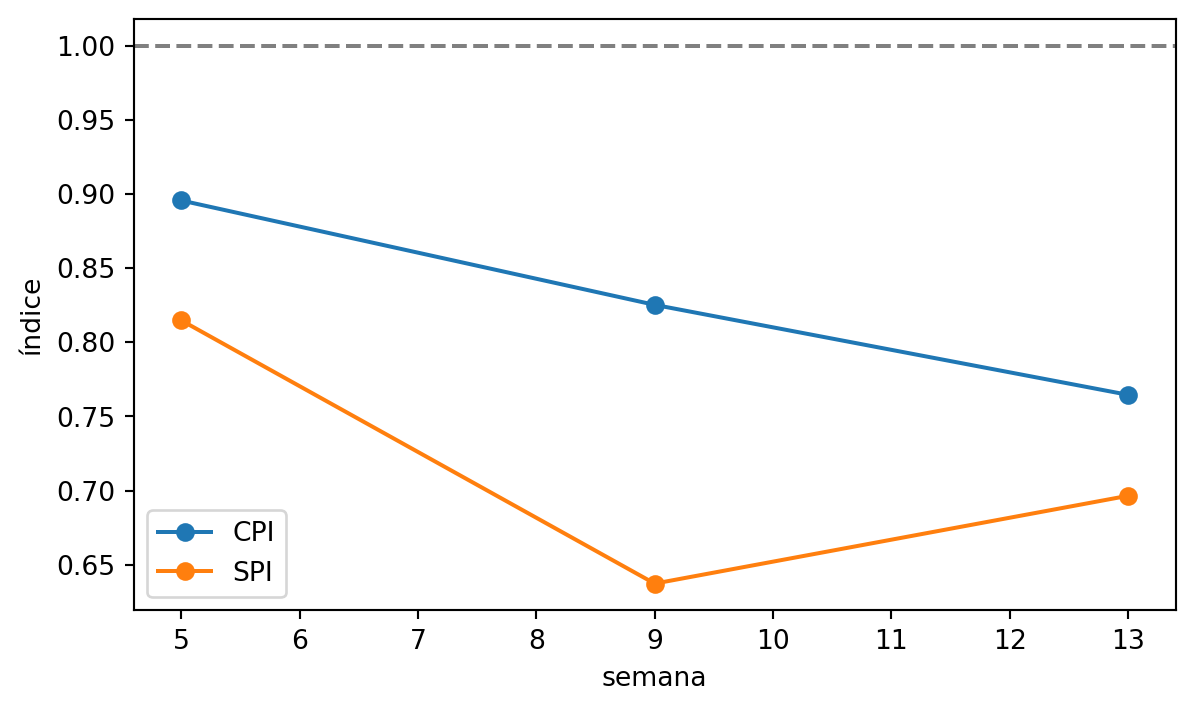

In [51]:
#| fig-cap: "Evolución de CPI y SPI"
#| label: fig-evolucion-p3
ax = indicadores[['CPI', 'SPI']].plot(marker='o', figsize=(7, 4))
ax.axhline(1, color='grey', linestyle='--'); ax.set_ylabel('índice');

## Apartado 3

In [52]:
display(Markdown(pregunta_3))

3. Calcule en cada punto la estimación del coste final EAC = BAC / CPI y comente la tendencia.  

In [53]:
indicadores['EAC'] = BAC_total / indicadores['CPI']
indicadores['VAC'] = BAC_total - indicadores['EAC']
indicadores[['CPI', 'EAC', 'VAC']].round({'CPI': 3, 'EAC': 1, 'VAC': 1})

,CPI,EAC,VAC
semana,,,
5,0.896,357.2,-37.2
9,0.825,387.7,-67.7
13,0.765,418.5,-98.5


## Apartado 4

In [54]:
display(Markdown(pregunta_4))

4. A la vista de la evolución, ¿el proyecto se está recuperando o deteriorando? ¿Qué decisiones tomaría tras el último punto de control?  

In [55]:
cpi = indicadores['CPI']; spi = indicadores['SPI']
tend_c = 'mejora' if cpi.iloc[-1] > cpi.iloc[0] else 'empeora'
tend_s = 'mejora' if spi.iloc[-1] > spi.iloc[0] else 'empeora'
Markdown(f'''Entre el primer y el último punto de control el CPI {tend_c} ({cpi.iloc[0]:.2f} → {cpi.iloc[-1]:.2f}) y el SPI {tend_s} ({spi.iloc[0]:.2f} → {spi.iloc[-1]:.2f}). La previsión de coste final pasa de {indicadores["EAC"].iloc[0]:.0f} a {indicadores["EAC"].iloc[-1]:.0f} k€ frente a un presupuesto de {BAC_total:.0f}. Conviene recordar que el SPI tiende a 1 al final del proyecto aunque haya retraso, así que su mejora en los últimos puntos puede ser aparente; para el plazo es preferible la programación ganada. Tras el último control procede revisar las actividades pendientes: acelerar las críticas (si el sobrecoste compensa la penalización o los costes indirectos) y revisar las causas del sobrecoste en las ya ejecutadas para que no se repitan.''')

Entre el primer y el último punto de control el CPI empeora (0.90 → 0.76) y el SPI empeora (0.81 → 0.70). La previsión de coste final pasa de 357 a 419 k€ frente a un presupuesto de 320. Conviene recordar que el SPI tiende a 1 al final del proyecto aunque haya retraso, así que su mejora en los últimos puntos puede ser aparente; para el plazo es preferible la programación ganada. Tras el último control procede revisar las actividades pendientes: acelerar las críticas (si el sobrecoste compensa la penalización o los costes indirectos) y revisar las causas del sobrecoste en las ya ejecutadas para que no se repitan.